# Multimodal LSTM for WEAR activity recognition

This notebook predicts one of **19 activities** from a one-second acceleration window, its body location, and aligned VideoMAE features. The [MLP baseline](mlp_baseline.ipynb) uses only acceleration; this model tests whether temporal modeling and video add useful information.

**Protocol.** Use 50 sensor readings at 50 Hz, move the window by 25 readings, require at least 80% label agreement, and hold out whole subjects for validation. Drop training or validation limb windows with missing acceleration readings, as in the MLP baseline. The test set has no labels, so missing test readings are filled with training-set means.

**How to read the run:** data counts and the class chart establish the sample mix; training curves show optimization; the validation report, confusion matrix, and per-limb/per-subject tables show where the model works; the final cell checks and saves the submission. Run the notebook from top to bottom. Saved outputs are intentionally cleared because the previous notebook mixed results from different code states.

In [1]:
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE)

PyTorch: 2.10.0+cpu | device: cpu


## 1. Configuration

Kaggle's attached dataset is used when present. For a local copy, set the WEAR_DATA_DIR environment variable. Outputs go to Kaggle's working directory or to a local outputs folder.

In [2]:
KAGGLE_DATA = Path("/kaggle/input/competitions/3rd-wear-dataset-challenge-hasca-2026")
DATA_DIR = Path(os.environ.get(
    "WEAR_DATA_DIR",
    KAGGLE_DATA if KAGGLE_DATA.exists() else Path("..") / "data",
))
OUTPUT_DIR = Path(os.environ.get(
    "WEAR_OUTPUT_DIR",
    "/kaggle/working" if Path("/kaggle/working").exists() else "outputs",
))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SENSOR_HZ, VIDEO_FPS = 50, 30
SENSOR_WINDOW, VIDEO_WINDOW, WINDOW_STRIDE = 50, 15, 25
VIDEO_OFFSET = 8  # central 15 of the 30 frames in a one-second interval
MIN_AGREEMENT = 0.80

HIDDEN_SIZE = 128
LSTM_LAYERS = 2
DROPOUT = 0.2
BATCH_SIZE = 128
EPOCHS = 10
PATIENCE = 6
LR = 2e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05
SEED = 42

LABELS = [
    "null", "jogging", "jogging (rotating arms)", "jogging (skipping)",
    "jogging (sidesteps)", "jogging (butt-kicks)", "stretching (triceps)",
    "stretching (lunging)", "stretching (shoulders)", "stretching (hamstrings)",
    "stretching (lumbar rotation)", "push-ups", "push-ups (complex)", "sit-ups",
    "sit-ups (complex)", "burpees", "lunges", "lunges (complex)", "bench-dips",
]
LABEL_TO_ID = {label: i for i, label in enumerate(LABELS)}
NUM_CLASSES = len(LABELS)
LOCATIONS = ["right_arm", "right_leg", "left_leg", "left_arm"]
LOCATION_TO_ID = {name: i for i, name in enumerate(LOCATIONS)}
SENSOR_COLUMNS = [f"{loc}_acc_{axis}" for loc in LOCATIONS for axis in "xyz"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Data:", DATA_DIR)
print("Outputs:", OUTPUT_DIR)
print("Maximum epochs:", EPOCHS)

Data: /kaggle/input/competitions/3rd-wear-dataset-challenge-hasca-2026
Outputs: /kaggle/working
Maximum epochs: 10


## 2. Build labeled sensor and video windows

Each recording must have both an inertial CSV and a VideoMAE feature array. A window is kept when at least 40 of its 50 sensor rows share a label and the matching video slice exists. Each valid limb makes one sample. Non-numeric or missing limb readings exclude that limb's sample instead of creating non-finite model inputs.

In [3]:
sensor_paths = sorted((DATA_DIR / "train" / "inertial_feat").glob("*.csv"))
if not sensor_paths:
    raise FileNotFoundError(f"No training CSV files in {DATA_DIR / 'train' / 'inertial_feat'}")

sensor_arrays, video_arrays, index_parts = [], [], []
window_offsets = np.arange(SENSOR_WINDOW, dtype=np.int32)
total_missing_limbs = 0

for rec_id, sensor_path in enumerate(sensor_paths):
    video_path = DATA_DIR / "train" / "videomae_feat" / f"{sensor_path.stem}.npy"
    if not video_path.exists():
        raise FileNotFoundError(f"Missing video features: {video_path}")

    df = pd.read_csv(
        sensor_path,
        usecols=["sbj_id", "label", *SENSOR_COLUMNS],
        low_memory=False,
    )
    values = df[SENSOR_COLUMNS].apply(pd.to_numeric, errors="coerce").to_numpy(
        dtype=np.float32
    )
    labels = df["label"].fillna("null").astype(str).str.strip().map(LABEL_TO_ID)
    if labels.isna().any():
        unknown = sorted(df.loc[labels.isna(), "label"].astype(str).unique())
        raise ValueError(f"{sensor_path.name}: unknown labels {unknown}")
    label_ids = labels.to_numpy(dtype=np.int64)
    subject = int(df["sbj_id"].iloc[0])

    video = np.load(video_path, mmap_mode="r")
    if video.ndim != 2 or video.shape[1] != 768:
        raise ValueError(f"{video_path.name}: expected (frames, 768), got {video.shape}")

    starts = np.arange(
        0, len(values) - SENSOR_WINDOW + 1, WINDOW_STRIDE, dtype=np.int32
    )
    window_idx = starts[:, None] + window_offsets
    counts = np.stack(
        [(label_ids[window_idx] == c).sum(axis=1) for c in range(NUM_CLASSES)],
        axis=1,
    )
    majority = counts.argmax(axis=1)
    video_starts = starts * VIDEO_FPS // SENSOR_HZ + VIDEO_OFFSET
    keep = (
        (counts.max(axis=1) >= MIN_AGREEMENT * SENSOR_WINDOW)
        & (video_starts + VIDEO_WINDOW <= len(video))
    )
    kept_starts, kept_labels, kept_idx = starts[keep], majority[keep], window_idx[keep]

    sensor_arrays.append(values)
    video_arrays.append(video)
    recording_samples = 0
    for loc_id in range(len(LOCATIONS)):
        limb_windows = values[kept_idx, 3 * loc_id: 3 * loc_id + 3]
        finite = np.isfinite(limb_windows).all(axis=(1, 2))
        count = int(finite.sum())
        total_missing_limbs += int((~finite).sum())
        recording_samples += count
        if count:
            index_parts.append(pd.DataFrame({
                "recording_id": rec_id,
                "start": kept_starts[finite],
                "location_id": loc_id,
                "label_id": kept_labels[finite],
                "sbj_id": subject,
            }))
    print(
        f"{sensor_path.stem:>9}: {len(kept_starts):5d}/{len(starts):5d} "
        f"aligned labeled windows -> {recording_samples:6d} limb samples"
    )

index = pd.concat(index_parts, ignore_index=True)
print(f"\nRecordings: {len(sensor_paths)} | samples: {len(index):,}")
print(f"Limb windows excluded for missing readings: {total_missing_limbs:,}")

    sbj_0:  5508/ 5588 aligned labeled windows ->  22032 limb samples
  sbj_0_2:  4437/ 4481 aligned labeled windows ->  17748 limb samples
    sbj_1:  5472/ 5555 aligned labeled windows ->  21888 limb samples
   sbj_10:  7905/ 7969 aligned labeled windows ->  29592 limb samples
   sbj_11:  4398/ 4443 aligned labeled windows ->  17592 limb samples
   sbj_12:  6468/ 6539 aligned labeled windows ->  25872 limb samples
   sbj_13:  7869/ 7955 aligned labeled windows ->  31476 limb samples
   sbj_14:  6329/ 6401 aligned labeled windows ->  25316 limb samples
 sbj_14_2:  6642/ 6709 aligned labeled windows ->  26568 limb samples
   sbj_15:  5154/ 5205 aligned labeled windows ->  20616 limb samples
   sbj_16:  6963/ 7019 aligned labeled windows ->  27852 limb samples
   sbj_17:  6103/ 6181 aligned labeled windows ->  24412 limb samples
   sbj_18:  5203/ 5263 aligned labeled windows ->  20812 limb samples
   sbj_19:  4172/ 4217 aligned labeled windows ->  16688 limb samples
    sbj_2:  7023/ 71

Null share: 39.6%
null                            216357
jogging                          19880
jogging (rotating arms)          17400
jogging (skipping)               18068
jogging (sidesteps)              19584
jogging (butt-kicks)             17032
stretching (triceps)             18508
stretching (lunging)             19388
stretching (shoulders)           17755
stretching (hamstrings)          18066
stretching (lumbar rotation)     18196
push-ups                         17032
push-ups (complex)               18308
sit-ups                          18920
sit-ups (complex)                19124
burpees                          18192
lunges                           18575
lunges (complex)                 19108
bench-dips                       16471


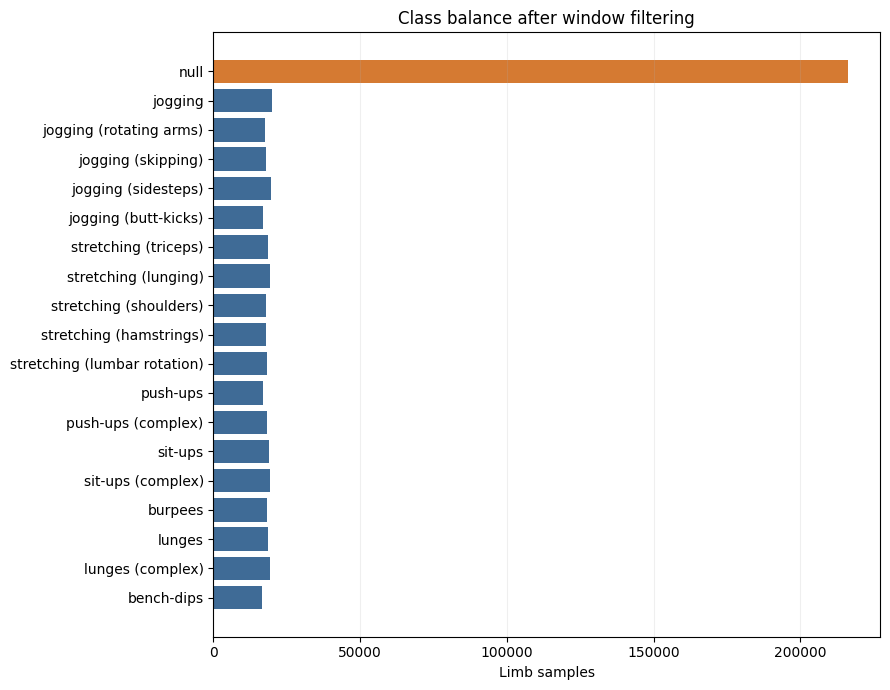

In [4]:
class_counts = (
    index["label_id"].value_counts()
    .reindex(range(NUM_CLASSES), fill_value=0)
)
print("Null share:", f"{class_counts.iloc[0] / len(index):.1%}")
print(pd.Series(class_counts.to_numpy(), index=LABELS).to_string())

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#d57a32" if i == 0 else "#3f6b96" for i in range(NUM_CLASSES)]
ax.barh(LABELS[::-1], class_counts.to_numpy()[::-1], color=colors[::-1])
ax.set(xlabel="Limb samples", title="Class balance after window filtering")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

## 3. Hold out subjects and fit sensor scaling

The split groups all windows from the same person. Normalization uses only training windows and is computed separately for each limb and axis, matching the MLP baseline's sensor protocol. This also verifies that all retained training values are finite.

In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_rows, val_rows = next(splitter.split(index, groups=index["sbj_id"]))
train_df = index.iloc[train_rows].reset_index(drop=True)
val_df = index.iloc[val_rows].reset_index(drop=True)
train_subjects = sorted(train_df["sbj_id"].unique().tolist())
val_subjects = sorted(val_df["sbj_id"].unique().tolist())
assert set(train_subjects).isdisjoint(val_subjects)
print("Train subjects:", train_subjects)
print("Validation subjects:", val_subjects)
print(f"Train samples: {len(train_df):,} | validation samples: {len(val_df):,}")

loc_sum = np.zeros((len(LOCATIONS), 3), dtype=np.float64)
loc_sum_sq = np.zeros_like(loc_sum)
loc_count = np.zeros(len(LOCATIONS), dtype=np.int64)

for (rec_id, loc_id), group in train_df.groupby(["recording_id", "location_id"]):
    starts = group["start"].to_numpy(dtype=np.int32)
    windows = sensor_arrays[int(rec_id)][
        starts[:, None] + window_offsets,
        3 * int(loc_id): 3 * int(loc_id) + 3,
    ]
    loc_sum[loc_id] += windows.sum(axis=(0, 1), dtype=np.float64)
    loc_sum_sq[loc_id] += np.square(windows, dtype=np.float64).sum(
        axis=(0, 1), dtype=np.float64
    )
    loc_count[loc_id] += windows.shape[0] * SENSOR_WINDOW

if (loc_count == 0).any():
    raise ValueError("A limb has no valid training windows.")
loc_mean = (loc_sum / loc_count[:, None]).astype(np.float32)
variance = np.maximum(loc_sum_sq / loc_count[:, None] - loc_mean ** 2, 0.0)
loc_std = np.sqrt(variance).astype(np.float32)
loc_std[loc_std < 1e-6] = 1.0
assert np.isfinite(loc_mean).all() and np.isfinite(loc_std).all()

print("\nTraining means by limb:")
print(pd.DataFrame(loc_mean, index=LOCATIONS, columns=["x", "y", "z"]).round(3))

Train subjects: [2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14, 16, 17, 18, 19, 20, 21]
Validation subjects: [0, 1, 8, 13, 15]
Train samples: 412,456 | validation samples: 133,508

Training means by limb:
               x      y      z
right_arm  0.417  0.413 -0.231
right_leg  0.726 -0.002  0.160
left_leg   0.627  0.031  0.153
left_arm  -0.406  0.387 -0.228


## 4. Dataset and input checks

The dataset reads a 50 × 3 acceleration slice and a central 15 × 768 video feature slice for each indexed sample. It uses arrays prepared above, so DataLoader workers are unnecessary. The next cell checks a real batch before any training starts.

In [6]:
class WearDataset(Dataset):
    def __init__(self, frame, sensor_arrays, video_arrays, loc_mean, loc_std):
        self.recording_ids = frame["recording_id"].to_numpy(dtype=np.int32)
        self.starts = frame["start"].to_numpy(dtype=np.int32)
        self.locations = frame["location_id"].to_numpy(dtype=np.int64)
        self.labels = frame["label_id"].to_numpy(dtype=np.int64)
        self.sensor_arrays = sensor_arrays
        self.video_arrays = video_arrays
        self.loc_mean = loc_mean
        self.loc_std = loc_std

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        rec_id = int(self.recording_ids[idx])
        start = int(self.starts[idx])
        loc_id = int(self.locations[idx])
        sensor = self.sensor_arrays[rec_id][
            start: start + SENSOR_WINDOW, 3 * loc_id: 3 * loc_id + 3
        ]
        sensor = (sensor - self.loc_mean[loc_id]) / self.loc_std[loc_id]
        video_start = start * VIDEO_FPS // SENSOR_HZ + VIDEO_OFFSET
        video = np.array(
            self.video_arrays[rec_id][video_start: video_start + VIDEO_WINDOW],
            dtype=np.float32,
            copy=True,
        )
        return {
            "sensor": torch.from_numpy(np.asarray(sensor, dtype=np.float32)),
            "video": torch.from_numpy(video),
            "location": torch.tensor(loc_id, dtype=torch.long),
            "label": torch.tensor(int(self.labels[idx]), dtype=torch.long),
        }


train_dataset = WearDataset(train_df, sensor_arrays, video_arrays, loc_mean, loc_std)
val_dataset = WearDataset(val_df, sensor_arrays, video_arrays, loc_mean, loc_std)
loader_settings = dict(num_workers=0, pin_memory=(DEVICE.type == "cuda"))
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_settings
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_settings
)

batch = next(iter(train_loader))
assert batch["sensor"].shape == (min(BATCH_SIZE, len(train_dataset)), 50, 3)
assert batch["video"].shape == (min(BATCH_SIZE, len(train_dataset)), 15, 768)
assert torch.isfinite(batch["sensor"]).all() and torch.isfinite(batch["video"]).all()
print("Sensor:", tuple(batch["sensor"].shape))
print("Video:", tuple(batch["video"].shape))
print("Labels:", tuple(batch["label"].shape))
print("First batch is finite.")

Sensor: (128, 50, 3)
Video: (128, 15, 768)
Labels: (128,)
First batch is finite.


## 5. Multimodal LSTM

One LSTM summarizes the acceleration sequence. A second LSTM summarizes projected VideoMAE features. A learned limb embedding tells the classifier where the acceleration came from. This is the active model; the inactive transformer reference from the earlier notebook has been removed.

In [7]:
class MultimodalLSTM(nn.Module):
    def __init__(self, num_classes, hidden_size, num_layers, dropout):
        super().__init__()
        lstm_dropout = dropout if num_layers > 1 else 0.0
        self.sensor_lstm = nn.LSTM(
            3, hidden_size, num_layers, batch_first=True, dropout=lstm_dropout
        )
        self.video_projection = nn.Sequential(
            nn.Linear(768, hidden_size), nn.LayerNorm(hidden_size), nn.GELU()
        )
        self.video_lstm = nn.LSTM(
            hidden_size, hidden_size, num_layers,
            batch_first=True, dropout=lstm_dropout,
        )
        self.location_embedding = nn.Embedding(len(LOCATIONS), hidden_size)
        self.classifier = nn.Sequential(
            nn.Linear(3 * hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, sensor, video, location):
        _, (sensor_hidden, _) = self.sensor_lstm(sensor)
        _, (video_hidden, _) = self.video_lstm(self.video_projection(video))
        features = torch.cat([
            sensor_hidden[-1],
            video_hidden[-1],
            self.location_embedding(location),
        ], dim=1)
        return self.classifier(features)


model = MultimodalLSTM(
    NUM_CLASSES, HIDDEN_SIZE, LSTM_LAYERS, DROPOUT
).to(DEVICE)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
with torch.no_grad():
    logits = model(
        batch["sensor"][:2].to(DEVICE),
        batch["video"][:2].to(DEVICE),
        batch["location"][:2].to(DEVICE),
    )
assert logits.shape == (2, NUM_CLASSES) and torch.isfinite(logits).all()
print("Model output:", tuple(logits.shape))

MultimodalLSTM(
  (sensor_lstm): LSTM(3, 128, num_layers=2, batch_first=True, dropout=0.2)
  (video_projection): Sequential(
    (0): Linear(in_features=768, out_features=128, bias=True)
    (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
  )
  (video_lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.2)
  (location_embedding): Embedding(4, 128)
  (classifier): Sequential(
    (0): Linear(in_features=384, out_features=128, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=19, bias=True)
  )
)
Trainable parameters: 615,315
Model output: (2, 19)


## 6. Train and select the best epoch

The frequent null class receives a smaller loss weight. Every epoch prints training and held-out validation loss, macro F1, and accuracy; the progress bars show activity within an epoch. History is saved after every epoch, and each new best checkpoint is saved immediately. Six epochs without improvement stop training. A non-finite loss raises an error immediately.

In [8]:
counts = np.bincount(train_df["label_id"], minlength=NUM_CLASSES).clip(min=1)
weights = np.clip(len(train_df) / (NUM_CLASSES * counts), 0.25, 5.0)
class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(
    weight=class_weights, label_smoothing=LABEL_SMOOTHING
)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


def run_epoch(loader, train):
    model.train(train)
    total_loss, predictions, targets = 0.0, [], []
    phase = "Train" if train else "Validation"
    with torch.set_grad_enabled(train):
        for batch in tqdm(loader, desc=phase, leave=False):
            sensor = batch["sensor"].to(DEVICE, non_blocking=True)
            video = batch["video"].to(DEVICE, non_blocking=True)
            location = batch["location"].to(DEVICE, non_blocking=True)
            target = batch["label"].to(DEVICE, non_blocking=True)
            logits = model(sensor, video, location)
            loss = criterion(logits, target)
            if not torch.isfinite(loss).item():
                raise RuntimeError(f"Non-finite {phase.lower()} loss; inspect the input batch.")
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += loss.item() * len(target)
            predictions.append(logits.argmax(1).detach().cpu().numpy())
            targets.append(target.cpu().numpy())
    predictions = np.concatenate(predictions)
    targets = np.concatenate(targets)
    return (
        total_loss / len(targets),
        f1_score(targets, predictions, average="macro", zero_division=0),
        accuracy_score(targets, predictions),
        targets,
        predictions,
    )


history, best_f1, best_state, wait = [], -1.0, None, 0
started = time.time()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_f1, train_acc, _, _ = run_epoch(train_loader, train=True)
    val_loss, val_f1, val_acc, _, _ = run_epoch(val_loader, train=False)
    scheduler.step()
    history.append({
        "epoch": epoch,
        "train_loss": train_loss, "train_f1": train_f1, "train_acc": train_acc,
        "val_loss": val_loss, "val_f1": val_f1, "val_acc": val_acc,
    })
    pd.DataFrame(history).to_csv(
        OUTPUT_DIR / "multimodal_lstm_history.csv", index=False
    )
    improved = val_f1 > best_f1
    print(
        f"Epoch {epoch:02d} | train loss {train_loss:.4f} F1 {train_f1:.4f} | "
        f"val loss {val_loss:.4f} F1 {val_f1:.4f} acc {val_acc:.4f}"
        f"{'  * best' if improved else ''}",
        flush=True,
    )
    if improved:
        best_f1, wait = val_f1, 0
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        torch.save(best_state, OUTPUT_DIR / "multimodal_lstm_best.pt")
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping after {PATIENCE} epochs without improvement.")
            break

assert best_state is not None
model.load_state_dict(best_state)
print(f"Training time: {time.time() - started:.0f} s | best val macro F1: {best_f1:.4f}")

Train:   0%|          | 0/3223 [00:00<?, ?it/s]

Validation:   0%|          | 0/1044 [00:00<?, ?it/s]

Epoch 01 | train loss 0.9726 F1 0.7597 | val loss 1.9696 F1 0.4978 acc 0.5720  * best


Train:   0%|          | 0/3223 [00:00<?, ?it/s]

Validation:   0%|          | 0/1044 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/1044 [00:00<?, ?it/s]

Epoch 07 | train loss 0.4654 F1 0.9902 | val loss 2.4856 F1 0.4710 acc 0.5780


Train:   0%|          | 0/3223 [00:00<?, ?it/s]

Validation:   0%|          | 0/1044 [00:00<?, ?it/s]

Epoch 08 | train loss 0.4569 F1 0.9944 | val loss 2.5227 F1 0.4653 acc 0.5746
Early stopping after 6 epochs without improvement.
Training time: 6777 s | best val macro F1: 0.5075


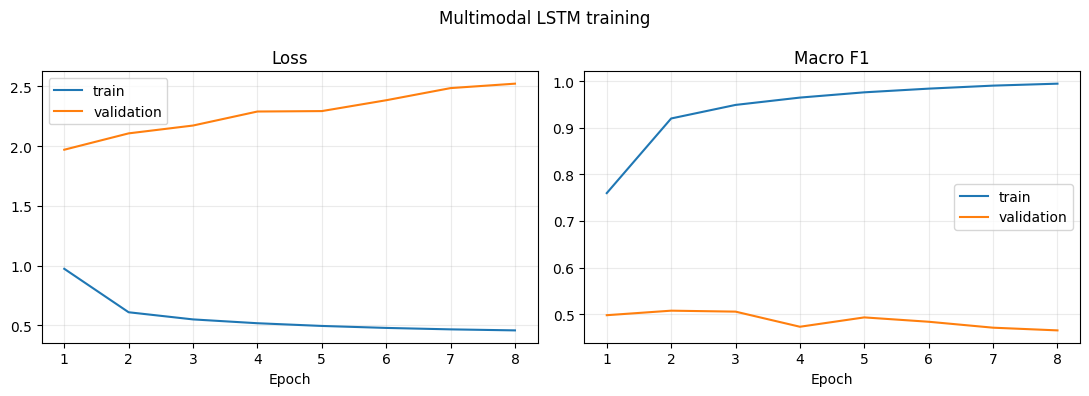

In [9]:
hist = pd.DataFrame(history)
hist.to_csv(OUTPUT_DIR / "multimodal_lstm_history.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for metric, ax in zip(("loss", "f1"), axes):
    ax.plot(hist["epoch"], hist[f"train_{metric}"], label="train")
    ax.plot(hist["epoch"], hist[f"val_{metric}"], label="validation")
    ax.set(xlabel="Epoch", title="Loss" if metric == "loss" else "Macro F1")
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("Multimodal LSTM training")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "multimodal_lstm_training.png", dpi=150)
plt.show()

## 7. Evaluate on unseen subjects

Restore the best checkpoint before this section. Macro F1 treats all 19 classes equally; the class report shows which movements are confused. The confusion matrix is normalized by true class, and the limb/subject tables reveal uneven performance.

In [10]:
val_loss, val_f1, val_acc, y_true, y_pred = run_epoch(val_loader, train=False)
precision, recall, _, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)
non_null = y_true != 0
results = pd.DataFrame([{
    "model": "Multimodal LSTM",
    "validation_accuracy": val_acc,
    "macro_precision": precision,
    "macro_recall": recall,
    "macro_f1": val_f1,
    "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    "macro_f1_without_null": f1_score(
        y_true[non_null], y_pred[non_null],
        labels=range(1, NUM_CLASSES), average="macro", zero_division=0,
    ),
    "parameters": sum(p.numel() for p in model.parameters()),
    "epochs_trained": len(history),
}])
results.to_csv(OUTPUT_DIR / "multimodal_lstm_results.csv", index=False)
print(results.T.to_string(header=False))

report = classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES),
    target_names=LABELS, digits=3, zero_division=0,
)
(OUTPUT_DIR / "multimodal_lstm_classification_report.txt").write_text(report)
print("\n" + report)

Validation:   0%|          | 0/1044 [00:00<?, ?it/s]

model                  Multimodal LSTM
validation_accuracy           0.599799
macro_precision               0.576753
macro_recall                  0.484761
macro_f1                      0.507539
weighted_f1                   0.577913
macro_f1_without_null         0.517977
parameters                      615315
epochs_trained                       8

                              precision    recall  f1-score   support

                        null      0.636     0.848     0.727     46820
                     jogging      0.631     0.552     0.589      5572
     jogging (rotating arms)      0.655     0.525     0.583      4920
          jogging (skipping)      0.489     0.506     0.497      4680
         jogging (sidesteps)      0.661     0.656     0.658      4944
        jogging (butt-kicks)      0.339     0.421     0.376      4544
        stretching (triceps)      0.495     0.222     0.307      4780
        stretching (lunging)      0.282     0.069     0.111      4892
      stretching 

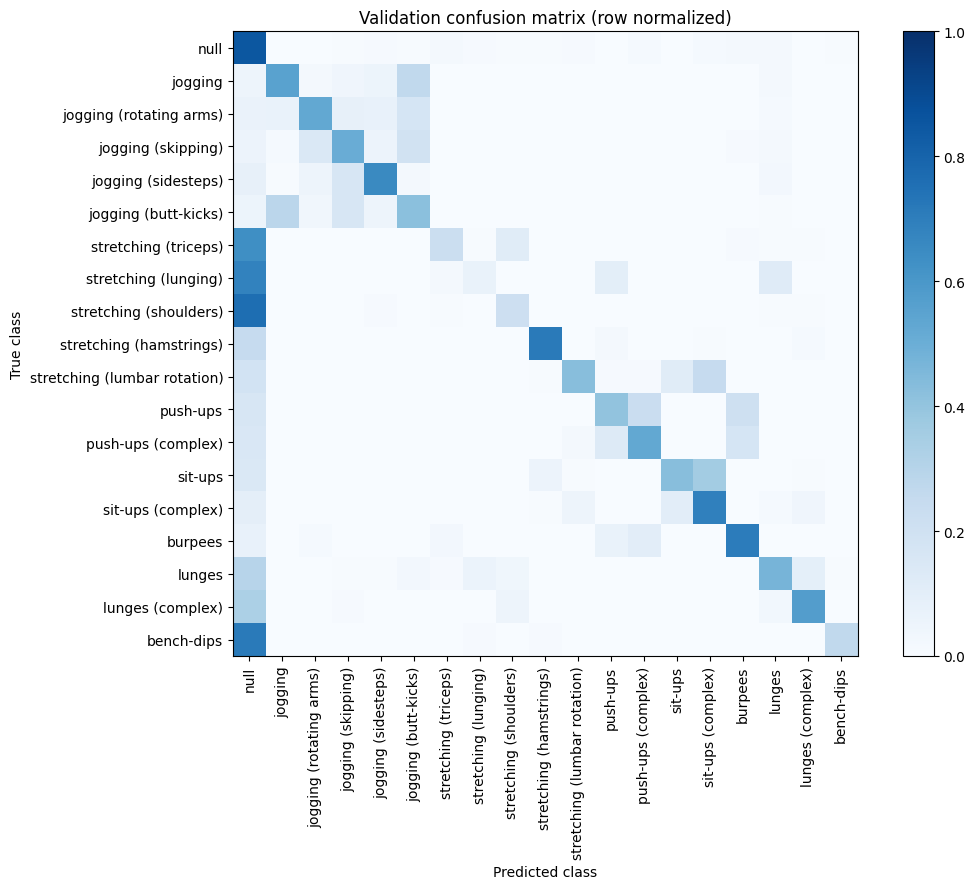

In [11]:
cm = confusion_matrix(
    y_true, y_pred, labels=range(NUM_CLASSES), normalize="true"
)
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), LABELS, rotation=90)
ax.set_yticks(range(NUM_CLASSES), LABELS)
ax.set(
    xlabel="Predicted class", ylabel="True class",
    title="Validation confusion matrix (row normalized)",
)
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "multimodal_lstm_confusion_matrix.png", dpi=150)
plt.show()

In [12]:
val_locations = val_df["location_id"].to_numpy()
val_subjects = val_df["sbj_id"].to_numpy()
assert len(y_true) == len(val_df)

per_limb = pd.DataFrame([{
    "limb": name,
    "samples": int((val_locations == loc_id).sum()),
    "accuracy": accuracy_score(
        y_true[val_locations == loc_id], y_pred[val_locations == loc_id]
    ),
    "macro_f1": f1_score(
        y_true[val_locations == loc_id], y_pred[val_locations == loc_id],
        average="macro", zero_division=0,
    ),
} for loc_id, name in enumerate(LOCATIONS)])
per_subject = pd.DataFrame([{
    "subject": subject,
    "samples": int((val_subjects == subject).sum()),
    "accuracy": accuracy_score(
        y_true[val_subjects == subject], y_pred[val_subjects == subject]
    ),
    "macro_f1": f1_score(
        y_true[val_subjects == subject], y_pred[val_subjects == subject],
        average="macro", zero_division=0,
    ),
} for subject in sorted(np.unique(val_subjects))])
per_limb.to_csv(OUTPUT_DIR / "multimodal_lstm_per_limb.csv", index=False)
per_subject.to_csv(OUTPUT_DIR / "multimodal_lstm_per_subject.csv", index=False)
print("By limb\n", per_limb.round(4).to_string(index=False))
print("\nBy held-out subject\n", per_subject.round(4).to_string(index=False))

By limb
      limb  samples  accuracy  macro_f1
right_arm    33377    0.5950    0.5007
right_leg    33377    0.6038    0.5135
 left_leg    33377    0.6052    0.5136
 left_arm    33377    0.5952    0.5016

By held-out subject
  subject  samples  accuracy  macro_f1
       0    39780    0.5128    0.4568
       1    21888    0.5323    0.4045
       8    19748    0.6049    0.5456
      13    31476    0.7563    0.6183
      15    20616    0.5955    0.4694
